In [1]:
import io
import tarfile

import numpy as np
import pandas as pd
import soundfile as sf
import soxr
import torch
from transformers import WhisperFeatureExtractor, WhisperForAudioClassification
from tqdm.notebook import trange

W1104 11:54:00.177000 76629 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
MODEL_DIR = "../models/ch_dialect_whisper/best-checkpoint-0"
DATA_DIR = "../data/stt4sg-350_v2-1"
SAMPLE_RATE = 16_000

class_nr_map = {'Zürich': 0, 'Innerschweiz': 1, 'Wallis': 2, 'Graubünden': 3, 'Ostschweiz': 4, 'Basel': 5, 'Bern': 6}
id2label = {i: name for name, i in class_nr_map.items()}

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
feature_extractor = WhisperFeatureExtractor.from_pretrained("openai/whisper-small")
model = WhisperForAudioClassification.from_pretrained(
        MODEL_DIR,
        id2label=id2label,
        label2id=class_nr_map
    ).to(device).eval()

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

In [ ]:
@torch.no_grad()
def classify(audios: list[np.ndarray]) -> pd.DataFrame:
    """Dialect probabilities of mono 16 kHz waveforms (one row per waveform)."""
    features = feature_extractor(audios, sampling_rate=SAMPLE_RATE, return_tensors="pt").input_features
    probs = model(features.to(device)).logits.softmax(-1).cpu().numpy()
    return pd.DataFrame(probs, columns=list(class_nr_map)).assign(pred=lambda d: d.idxmax(axis=1))


def load_audio(data: bytes) -> np.ndarray:
    audio, sr = sf.read(io.BytesIO(data), dtype="float32")
    if audio.ndim > 1:
        audio = audio.mean(1)
    return soxr.resample(audio, sr, SAMPLE_RATE) if sr != SAMPLE_RATE else audio

In [ ]:
N = 2056
meta = pd.read_csv(f"{DATA_DIR}/test.tsv", sep="\t", quoting=3).set_index("path")

paths, audios = [], []
with tarfile.open(f"{DATA_DIR}/clips__test.tar") as tar:
    for member in tar:
        if member.isfile() and member.name in meta.index:
            paths.append(member.name)
            audios.append(load_audio(tar.extractfile(member).read()))
            if len(paths) == N:
                break

preds = pd.concat([classify(audios[i: i + 16]) for i in trange(0, N, 16)], ignore_index=True)
preds.insert(0, "true", meta.loc[paths, "dialect_region"].to_numpy())
print(f"accuracy: {(preds.pred == preds.true).mean():.2f}")
preds.round(2).head(10)

  0%|          | 0/129 [00:00<?, ?it/s]

accuracy: 0.46


,true,Zürich,Innerschweiz,Wallis,Graubünden,Ostschweiz,Basel,Bern,pred
0,Bern,0.00,0.00,0.05,0.00,0.08,0.86,0.01,Basel
1,Ostschweiz,0.00,0.00,0.00,0.00,1.00,0.00,0.00,Ostschweiz
2,Basel,0.20,0.00,0.01,0.01,0.56,0.21,0.00,Ostschweiz
3,Innerschweiz,0.00,0.00,0.83,0.01,0.16,0.00,0.00,Wallis
4,Innerschweiz,0.94,0.03,0.00,0.00,0.00,0.02,0.01,Zürich
5,Wallis,0.00,0.00,0.00,0.00,1.00,0.00,0.00,Ostschweiz
6,Graubünden,0.00,0.00,0.11,0.86,0.02,0.00,0.00,Graubünden
7,Graubünden,0.00,0.00,1.00,0.00,0.00,0.00,0.00,Wallis
8,Basel,0.00,0.00,0.00,0.00,1.00,0.00,0.00,Ostschweiz
9,Ostschweiz,0.00,0.00,0.00,0.00,1.00,0.00,0.00,Ostschweiz


In [5]:
regions = list(class_nr_map)
p_true = preds[regions].to_numpy()[np.arange(len(preds)), preds.true.map(class_nr_map)]
scores = pd.DataFrame({"correct": preds.pred == preds.true, "log_loss": -np.log(p_true.clip(1e-12))})
print(f"log loss: {scores.log_loss.mean():.3f}")

per_class = scores.groupby(preds.true).agg(
    n=("correct", "size"), accuracy=("correct", "mean"), log_loss=("log_loss", "mean"))
per_class.loc["(macro mean)"] = [per_class.n.sum(), per_class.accuracy.mean(), per_class.log_loss.mean()]
per_class.round(2)

log loss: 3.408


,n,accuracy,log_loss
true,,,
Basel,333,0.32,4.28
Bern,299,0.40,3.72
Graubünden,306,0.42,3.66
Innerschweiz,277,0.10,6.44
Ostschweiz,282,0.92,0.30
Wallis,282,0.88,0.57
Zürich,277,0.22,4.78
(macro mean),2056,0.47,3.39


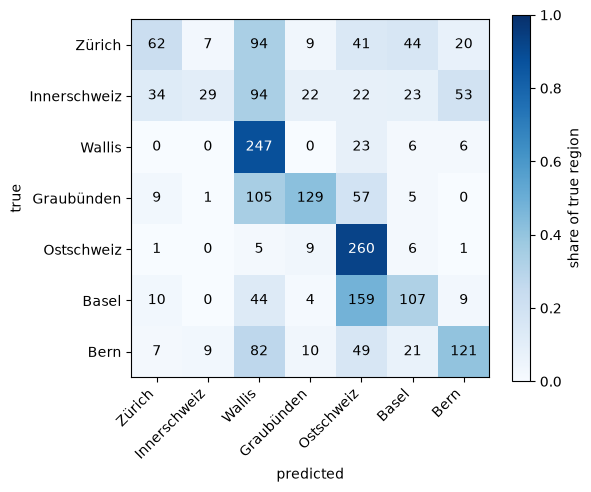

In [6]:
import matplotlib.pyplot as plt

confusion = pd.crosstab(preds.true, preds.pred).reindex(index=regions, columns=regions, fill_value=0)
share = confusion.div(confusion.sum(axis=1).clip(lower=1), axis=0)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
for i in range(len(regions)):
    for j in range(len(regions)):
        ax.text(j, i, confusion.iat[i, j], ha="center", va="center",
                color="white" if share.iat[i, j] > 0.5 else "black")
ax.set_xticks(range(len(regions)), regions, rotation=45, ha="right")
ax.set_yticks(range(len(regions)), regions)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
fig.colorbar(im, ax=ax, label="share of true region")
fig.tight_layout()